# 01 — Exploratory Data Analysis

Daily sales for **10 stores x 50 items over 2013-2017** (913k rows). Before engineering features or training models, this notebook answers four questions:

1. How does total demand evolve over time — is there trend and yearly seasonality?
2. Is there a weekly cycle?
3. How different are stores and items from each other?
4. How noisy is a single (store, item) series — the actual unit we will forecast?

- **Input:** `data/raw/train.csv`
- **Output:** figures saved to `outputs/figures/`

In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# Palette (validated categorical order + single-hue sequential ramp)
PALETTE = ["#2a78d6", "#008300", "#e87ba4", "#eda100", "#1baf7a", "#eb6834", "#4a3aa7", "#e34948"]
BLUE = PALETTE[0]
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv("../data/raw/train.csv", parse_dates=["date"])
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
print(df.shape)
df.head()

(913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 1. The big picture — total demand over time

Summing all stores and items into one weekly series makes the two macro patterns visible at once: a steady upward **trend** and a strong **yearly cycle**.

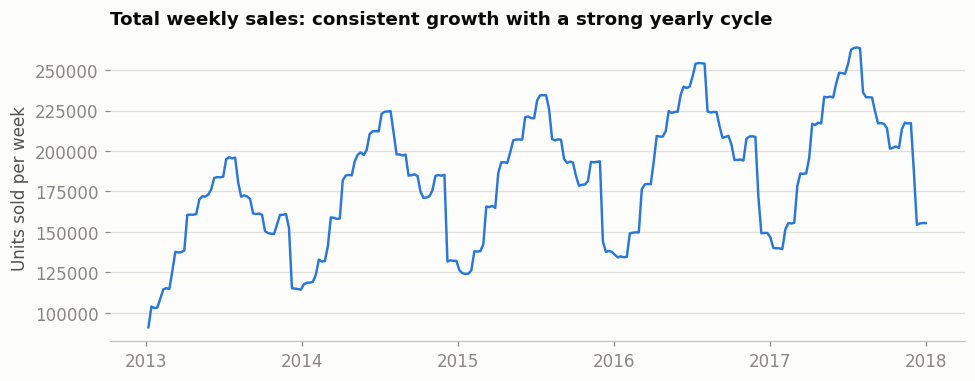

Year-over-year growth (%):
date
2014    15.0
2015     4.4
2016     8.6
2017     3.6


In [3]:
weekly = df.set_index("date")["sales"].resample("W").sum()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(weekly.index, weekly.values, color=BLUE, linewidth=1.6)
ax.set_title("Total weekly sales: consistent growth with a strong yearly cycle")
ax.set_ylabel("Units sold per week")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_01_weekly_sales.png", dpi=150, bbox_inches="tight")
plt.show()

yearly = df.groupby(df["date"].dt.year)["sales"].sum()
print("Year-over-year growth (%):")
print(yearly.pct_change().mul(100).round(1).dropna().to_string())

## 2. Yearly seasonality and growth, together

Averaging daily sales per **month x year** cell separates the two effects: reading a row left-to-right shows growth; reading a column top-to-bottom shows the seasonal shape (single-hue ramp — darker = more sales).

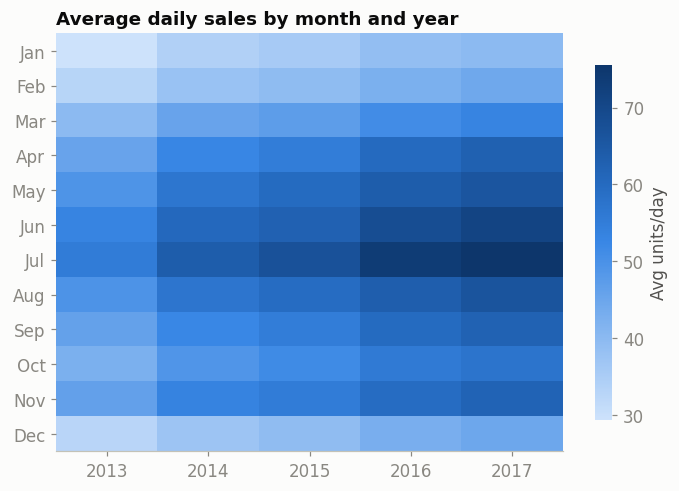

Peak month: 7 | Trough month: 1


In [4]:
pivot = (df.assign(year=df["date"].dt.year, month=df["date"].dt.month)
           .pivot_table(index="month", columns="year", values="sales", aggfunc="mean"))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
im = ax.imshow(pivot.values, cmap=SEQ_BLUE, aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Average daily sales by month and year")
ax.grid(visible=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Avg units/day", color=INK2)
cbar.ax.tick_params(color=MUTED, labelcolor=MUTED)
cbar.outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_02_month_year_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

peak, trough = pivot.mean(axis=1).idxmax(), pivot.mean(axis=1).idxmin()
print(f"Peak month: {peak} | Trough month: {trough}")

## 3. The weekly cycle

Retail demand rarely treats all weekdays equally. Average sales per day of week reveal how much of the short-term variation is just the calendar.

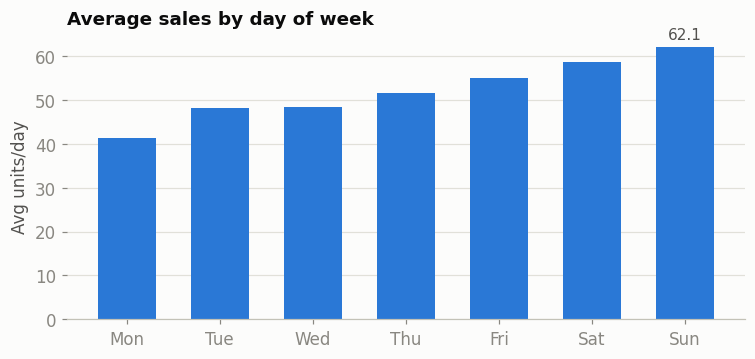

Peak day sells 50% more than the slowest day


In [5]:
dow = df.groupby(df["date"].dt.dayofweek)["sales"].mean()
labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(labels, dow.values, color=BLUE, width=0.62)
peak_i = int(dow.values.argmax())
ax.bar_label(bars, labels=[f"{v:.1f}" if i == peak_i else "" for i, v in enumerate(dow.values)],
             padding=3, color=INK2, fontsize=10)
ax.set_title("Average sales by day of week")
ax.set_ylabel("Avg units/day")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_03_day_of_week.png", dpi=150, bbox_inches="tight")
plt.show()

lift = (dow.max() / dow.min() - 1) * 100
print(f"Peak day sells {lift:.0f}% more than the slowest day")

## 4. Cross-section: how different are stores and items?

The forecasting unit is a (store, item) pair — 500 series in total. Two views of how heterogeneous they are: total volume per store, and the distribution of item-level average daily sales.

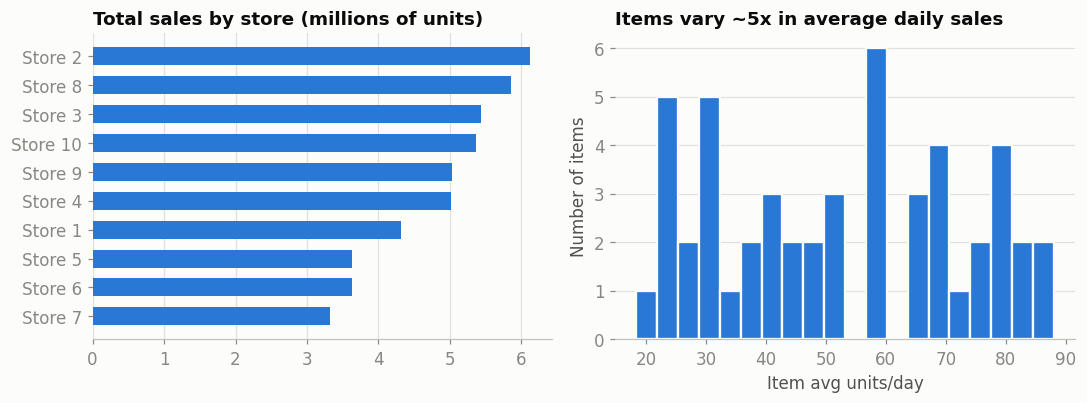

Store volume ratio (largest/smallest): 1.84x
Item avg daily sales: min 18.4, max 88.0


In [6]:
store_totals = df.groupby("store")["sales"].sum().sort_values()
item_avgs = df.groupby("item")["sales"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))

ax1.barh([f"Store {s}" for s in store_totals.index], store_totals.values / 1e6,
         color=BLUE, height=0.62)
ax1.set_title("Total sales by store (millions of units)")
ax1.grid(axis="x")
ax1.grid(axis="y", visible=False)

ax2.hist(item_avgs.values, bins=20, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax2.set_title("Items vary ~5x in average daily sales")
ax2.set_xlabel("Item avg units/day")
ax2.set_ylabel("Number of items")
ax2.grid(axis="y")
ax2.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_04_stores_items.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Store volume ratio (largest/smallest): {store_totals.max() / store_totals.min():.2f}x")
print(f"Item avg daily sales: min {item_avgs.min():.1f}, max {item_avgs.max():.1f}")

## 5. One series up close

Aggregates hide the noise the model actually faces. A single (store, item) series is integer-valued, low-volume and noisy — the seasonal signal only emerges through smoothing (28-day rolling mean).

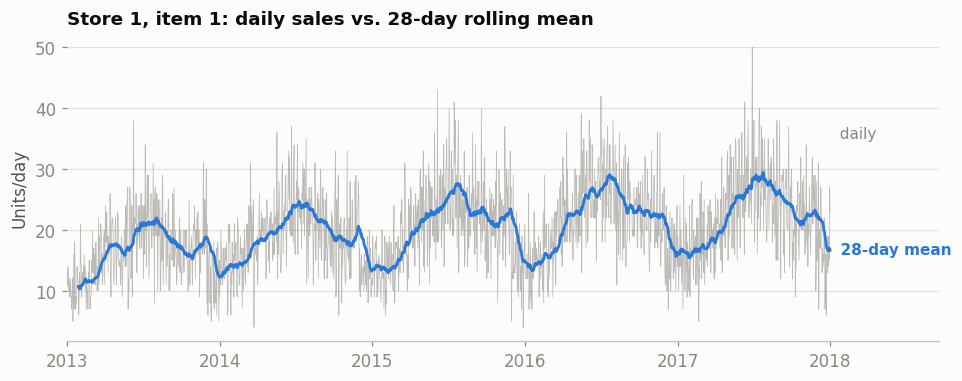

Daily coefficient of variation: 0.34


In [7]:
one = df[(df["store"] == 1) & (df["item"] == 1)].set_index("date")["sales"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(one.index, one.values, color=MUTED, linewidth=0.5, alpha=0.55)
ax.plot(one.index, one.rolling(28).mean(), color=BLUE, linewidth=1.8)
ax.text(one.index[-1], one.rolling(28).mean().iloc[-1], "  28-day mean",
        color=BLUE, fontsize=10, fontweight="bold", va="center")
ax.text(one.index[-1], one.values[-100:].max() * 0.97, "  daily",
        color=MUTED, fontsize=10, va="center")
ax.set_title("Store 1, item 1: daily sales vs. 28-day rolling mean")
ax.set_ylabel("Units/day")
ax.set_xlim(one.index[0], one.index[-1] + pd.Timedelta(days=260))
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_05_single_series.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Daily coefficient of variation: {one.std() / one.mean():.2f}")

## Findings

1. **Trend:** total demand grows every year — models need a way to capture level shifts (year feature, recent lags).
2. **Yearly seasonality:** strong and stable mid-year peak, winter trough — justifies `sales_lag_365`, `month` and `dayofyear` features.
3. **Weekly cycle:** a large, consistent day-of-week effect — justifies `dayofweek`, `is_weekend` and weekly-aligned lags (7/14/28).
4. **Heterogeneity:** stores differ ~2x in volume and items ~5x — `store` and `item` must be model inputs (categorical or via lags that carry each series' level).
5. **Noise:** individual series are noisy, integer-valued counts — rolling means/stds are informative features, and evaluation should aggregate errors across all 500 series.

These conclusions directly motivate the feature set built in [`02_feature_engineering.ipynb`](02_feature_engineering.ipynb).